# 7. Neighborhood typology

k-means clustering on nine standardized characteristics groups tracts into types, so places can be
described as a whole rather than one variable at a time. Script: `scripts/14_typology.py`.

_Part of the Chicago Energy Burden project (James Rocco Quantitative Data Research Scholarship, Lake Forest College). Run the pipeline scripts first, or read the executed copy on GitHub._

In [1]:
import json, warnings
import numpy as np, pandas as pd, geopandas as gpd
from IPython.display import Image, Markdown, display
from ceb import config
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
T, F = config.TABLES, config.FIGURES
gdf = gpd.read_file(config.PROCESSED / "chicago_tracts.gpkg")
sample = gdf[gdf["in_main_sample"].astype(bool)].reset_index(drop=True)
print(f"{len(gdf)} tracts mostly inside Chicago; {len(sample)} in the analysis sample")

782 tracts mostly inside Chicago; 768 in the analysis sample


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
feats = ["burden_pct", "ln_income", "pct_black", "pct_hispanic", "pct_pre1950", "pct_renter", "pct_multifam5", "pct_elec_heat"]
s = sample.assign(ln_avg_energy_cost=np.log(sample["avg_energy_cost"])).dropna(subset=feats)
X = StandardScaler().fit_transform(s[feats + ["ln_avg_energy_cost"]])
pd.DataFrame({"k": range(3, 9), "silhouette": [silhouette_score(X, KMeans(k, n_init=20, random_state=1).fit_predict(X)) for k in range(3, 9)]}).round(3)

,k,silhouette
0,3,0.306
1,4,0.278
2,5,0.279
3,6,0.277
4,7,0.258
5,8,0.252


In [3]:
pd.read_csv(T / "typology_profiles.csv").round(2)

,type,burden_pct,pct_black,pct_hispanic,pct_pre1950,pct_renter,pct_multifam5,pct_elec_heat,households,tracts,median_income,avg_energy_cost,label,share_in_high_burden_clusters
0,1,5.46,84.75,9.90,54.51,60.10,23.42,11.29,239768.80,231,38971.55,2896.17,"High burden: high Black share, low income",0.66
1,2,2.70,6.23,44.24,55.90,44.23,20.83,7.63,491532.54,379,83964.62,2675.56,"Moderate burden: low Black share, high Hispani...",0.05
2,3,1.60,23.73,10.46,34.90,67.76,78.54,30.67,322908.58,158,71611.05,1461.34,"Low burden: high large-building share, low ene...",0.01


In [4]:
pd.read_csv(T / "typology_by_cluster.csv")

,type,High-High,Low-High,Low-Low,Not significant
0,1,153,1,1,76
1,2,20,1,104,254
2,3,2,1,98,57


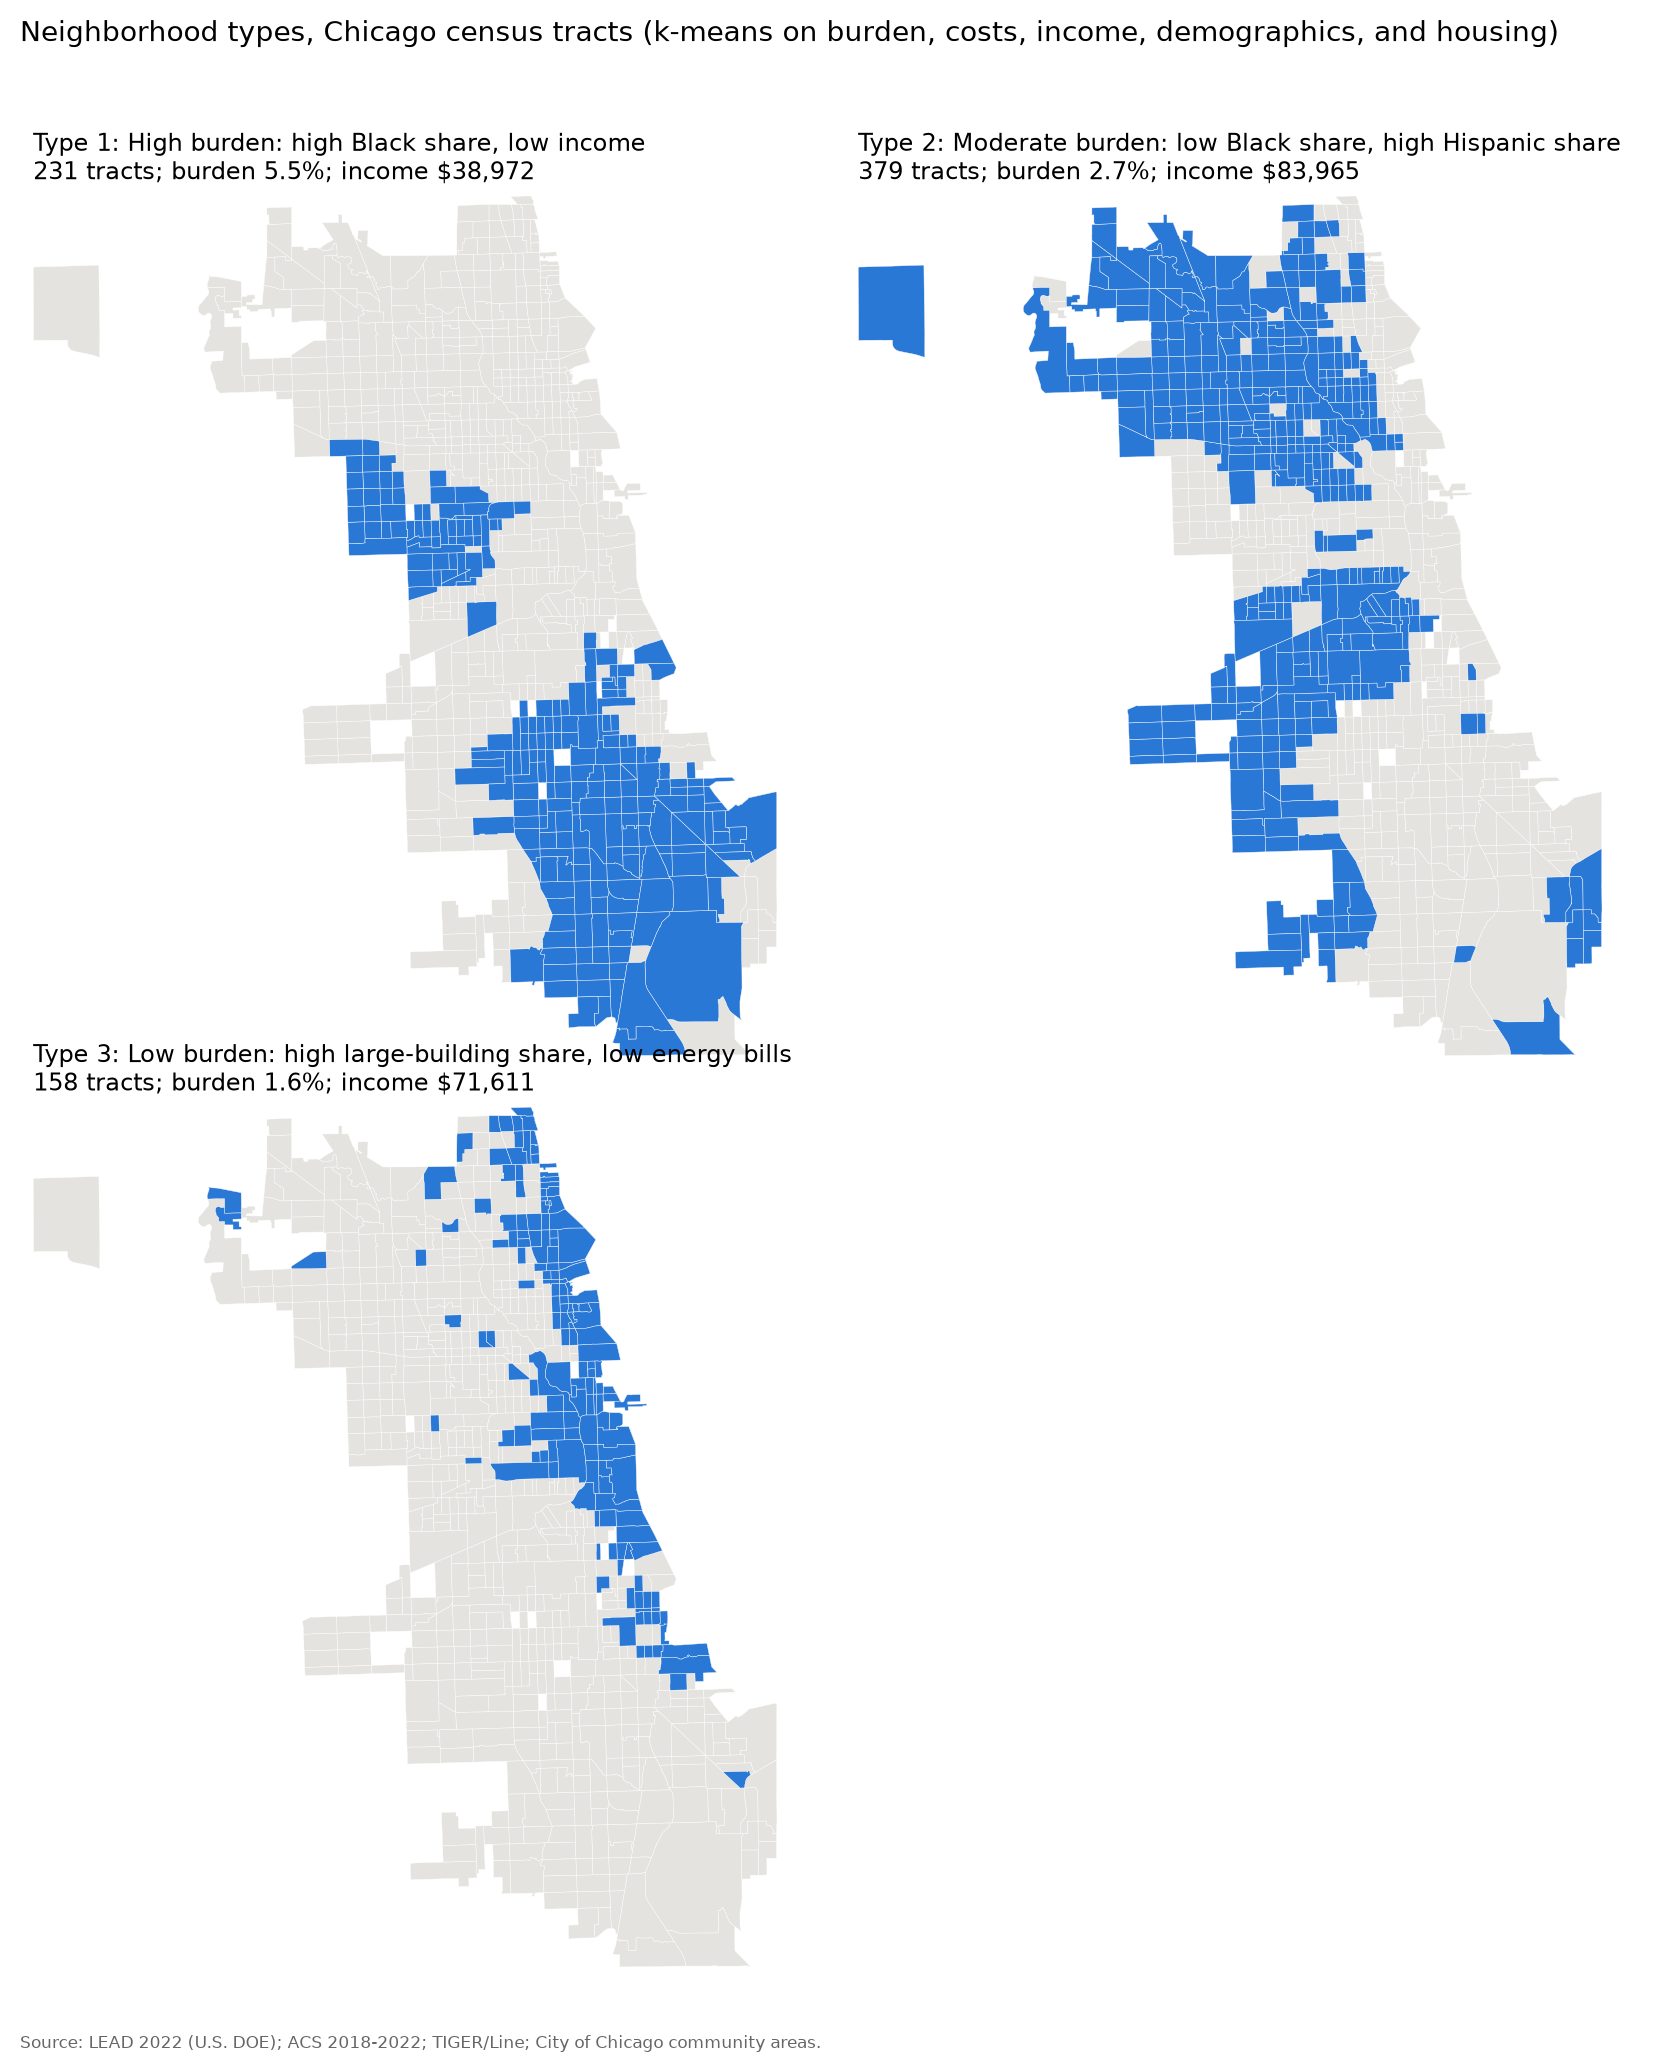

In [5]:
display(Image(F / "map_typology.png", width=900))